# Estimación diaria de energía solar — Sevilla

Notebook reproducible para estimar la irradiación solar diaria a partir de meteorología y calendario. El objetivo es `shortwave_radiation_sum` de Open-Meteo, convertido de MJ/m²/día a kWh/m²/día. Es una estimación retrospectiva diaria: las variables meteorológicas diarias observadas no son un pronóstico disponible por adelantado.

**Control de fuga:** como el objetivo se deriva de la irradiancia, no se usan como predictores irradiancia, radiación, insolación ni variables que la reexpresen. El ajuste y selección temporal no usan el test de 2024.

## 1. Configuración y dependencias

Entorno requerido: Python 3.10+. Instala en tu entorno antes de ejecutar: `python -m pip install pandas numpy requests matplotlib scikit-learn statsmodels joblib jupyterlab`. Ejecuta el notebook desde la raíz del repositorio. Las carpetas de datos y figuras se crean automáticamente.

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_validate

LATITUDE = 37.3891
LONGITUDE = -5.9845
CITY = "Sevilla"
TIMEZONE = "Europe/Madrid"
START_DATE = "2015-01-01"
END_DATE = "2024-12-31"
TARGET = "solar_energy_kwh_m2"
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
FIGURES_DIR = Path("reports/figures")
for directory in (RAW_DIR, PROCESSED_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Comprobación dimensional: 1 kWh = 3.6 MJ.
assert np.isclose(3.6 / 3.6, 1.0)
print(f"Configuración lista para {CITY}: {START_DATE} a {END_DATE}")

Configuración lista para Sevilla: 2015-01-01 a 2024-12-31


## 2. Descarga de Open-Meteo

Se descargan variables meteorológicas horarias y el total diario oficial de radiación de onda corta. El API devuelve `shortwave_radiation_sum` en MJ/m²/día. Se conserva localmente la respuesta original para poder reproducir el preprocesamiento.

In [2]:
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_COLUMNS = [
    "temperature_2m", "relative_humidity_2m", "cloud_cover", "wind_speed_10m"
]
DAILY_COLUMNS = ["shortwave_radiation_sum", "daylight_duration"]

def download_open_meteo() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Descarga observaciones horarias y objetivo diario para la ubicación configurada."""
    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "hourly": ",".join(HOURLY_COLUMNS),
        "daily": ",".join(DAILY_COLUMNS),
        "timezone": TIMEZONE,
    }
    try:
        response = requests.get(OPEN_METEO_URL, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()
    except requests.RequestException as exc:
        raise RuntimeError(f"Falló la descarga de Open-Meteo: {exc}") from exc
    except ValueError as exc:
        raise RuntimeError("Open-Meteo no devolvió una respuesta JSON válida.") from exc

    for section, required in (("hourly", ["time", *HOURLY_COLUMNS]),
                              ("daily", ["time", *DAILY_COLUMNS])):
        if section not in payload:
            raise ValueError(f"La respuesta no contiene la sección requerida: {section}")
        missing = set(required).difference(payload[section])
        if missing:
            raise ValueError(f"Faltan columnas de Open-Meteo en {section}: {sorted(missing)}")

    hourly = pd.DataFrame(payload["hourly"])
    daily = pd.DataFrame(payload["daily"])
    hourly.to_csv(RAW_DIR / "open_meteo_hourly.csv", index=False)
    daily.to_csv(RAW_DIR / "open_meteo_daily.csv", index=False)
    return hourly, daily

hourly_raw, daily_raw = download_open_meteo()
print(f"Registros horarios: {len(hourly_raw):,}; días: {len(daily_raw):,}")

Registros horarios: 87,672; días: 3,653


## 3. Limpieza, agregación horaria y conversión de unidades

Las mediciones horarias de temperatura, humedad, nubosidad y viento se agregan como medias por fecha local (no se suman). La energía objetivo proviene del total diario suministrado por Open-Meteo y se convierte con `MJ/m² ÷ 3.6 = kWh/m²`. No se suman muestras horarias de irradiancia, que son potencias en W/m² y no la energía diaria integrada.

In [3]:
def preprocess_data(hourly: pd.DataFrame, daily: pd.DataFrame) -> pd.DataFrame:
    """Agrega meteorología horaria por día y construye el objetivo en kWh/m²/día."""
    hourly_required = {"time", *HOURLY_COLUMNS}
    daily_required = {"time", *DAILY_COLUMNS}
    if missing := hourly_required.difference(hourly.columns):
        raise ValueError(f"Faltan columnas horarias: {sorted(missing)}")
    if missing := daily_required.difference(daily.columns):
        raise ValueError(f"Faltan columnas diarias: {sorted(missing)}")

    hourly_data = hourly.copy()
    daily_data = daily.copy()
    hourly_data["time"] = pd.to_datetime(hourly_data["time"], errors="coerce")
    daily_data["time"] = pd.to_datetime(daily_data["time"], errors="coerce")
    hourly_data = hourly_data.dropna(subset=["time"])
    daily_data = daily_data.dropna(subset=["time"])
    hourly_data["date"] = hourly_data["time"].dt.normalize()
    daily_data["date"] = daily_data["time"].dt.normalize()

    hourly_features = hourly_data.groupby("date", as_index=False).agg(
        temperature_mean=("temperature_2m", "mean"),
        temperature_max_hourly=("temperature_2m", "max"),
        relative_humidity_mean=("relative_humidity_2m", "mean"),
        cloud_cover_mean=("cloud_cover", "mean"),
        wind_speed_mean=("wind_speed_10m", "mean"),
    )
    daily_data = daily_data.rename(columns={"shortwave_radiation_sum": "shortwave_radiation_sum_mj_m2"})
    daily_data["shortwave_radiation_sum_mj_m2"] = pd.to_numeric(
        daily_data["shortwave_radiation_sum_mj_m2"], errors="coerce"
    )
    daily_data[TARGET] = daily_data["shortwave_radiation_sum_mj_m2"] / 3.6
    if (daily_data[TARGET].dropna() < 0).any():
        raise ValueError("El objetivo de energía solar no puede ser negativo.")
    result = daily_data.merge(hourly_features, on="date", how="inner", validate="one_to_one")
    result = result.sort_values("date").reset_index(drop=True)
    if result.empty:
        raise ValueError("No hay días comunes entre las series horaria y diaria.")
    return result

solar_df = preprocess_data(hourly_raw, daily_raw)
processed_path = PROCESSED_DIR / "solar_dataset.csv"
solar_df.to_csv(processed_path, index=False)
display(solar_df.head())
print(f"Dataset diario guardado en {processed_path}; {len(solar_df):,} días")

,time,shortwave_radiation_sum_mj_m2,daylight_duration,date,solar_energy_kwh_m2,temperature_mean,temperature_max_hourly,relative_humidity_mean,cloud_cover_mean,wind_speed_mean
0,2015-01-01,10.86,34695.59,2015-01-01,3.016667,7.508333,15.3,65.750000,0.000000,9.541667
1,2015-01-02,10.65,34733.95,2015-01-02,2.958333,9.087500,15.4,70.041667,4.625000,9.491667
2,2015-01-03,10.68,34776.01,2015-01-03,2.966667,9.754167,17.0,65.958333,0.000000,9.020833
3,2015-01-04,10.91,34821.67,2015-01-04,3.030556,9.675000,17.6,69.791667,0.000000,6.233333
4,2015-01-05,10.65,34870.81,2015-01-05,2.958333,8.420833,14.7,83.083333,7.583333,4.920833


Dataset diario guardado en data\processed\solar_dataset.csv; 3,653 días


## 4. Exploración de datos

Se visualiza la serie objetivo y la matriz de correlación de predictores usando solo el periodo de entrenamiento. Las figuras se guardan en `reports/figures/`.

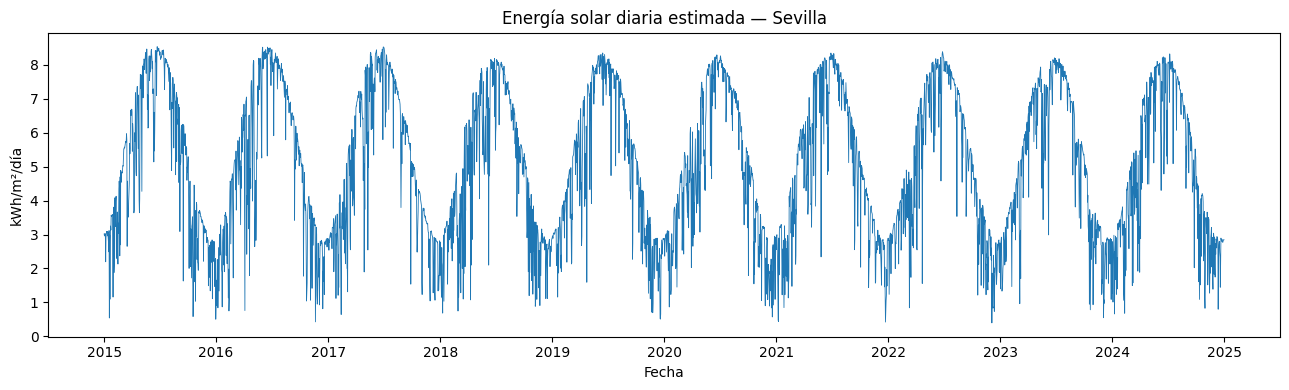

Resumen del conjunto de entrenamiento (hasta 2022):


,count,mean,min,25%,50%,75%,max,std
time,2922,2018-12-31 12:00:00,2015-01-01 00:00:00,2016-12-31 06:00:00,2018-12-31 12:00:00,2020-12-30 18:00:00,2022-12-31 00:00:00,NaN
shortwave_radiation_sum_mj_m2,2922.0,18.074648,1.43,11.12,17.96,25.575,30.72,7.808378
daylight_duration,2922.0,43886.882909,34502.19,37693.57,43975.135,50100.6275,53061.01,6386.122016
date,2922,2018-12-31 12:00:00,2015-01-01 00:00:00,2016-12-31 06:00:00,2018-12-31 12:00:00,2020-12-30 18:00:00,2022-12-31 00:00:00,NaN
solar_energy_kwh_m2,2922.0,5.020735,0.397222,3.088889,4.988889,7.104167,8.533333,2.168994
temperature_mean,2922.0,19.359999,4.633333,13.584375,18.445833,25.279167,37.283333,6.921031
temperature_max_hourly,2922.0,25.59668,7.6,18.425,24.3,32.7,45.3,8.078758
relative_humidity_mean,2922.0,61.926435,14.166667,48.71875,62.833333,75.458333,96.625,16.712896
cloud_cover_mean,2922.0,35.93345,0.0,5.75,29.041667,61.739583,100.0,31.3282
wind_speed_mean,2922.0,9.255335,3.475,6.91875,8.514583,10.866667,31.929167,3.380017


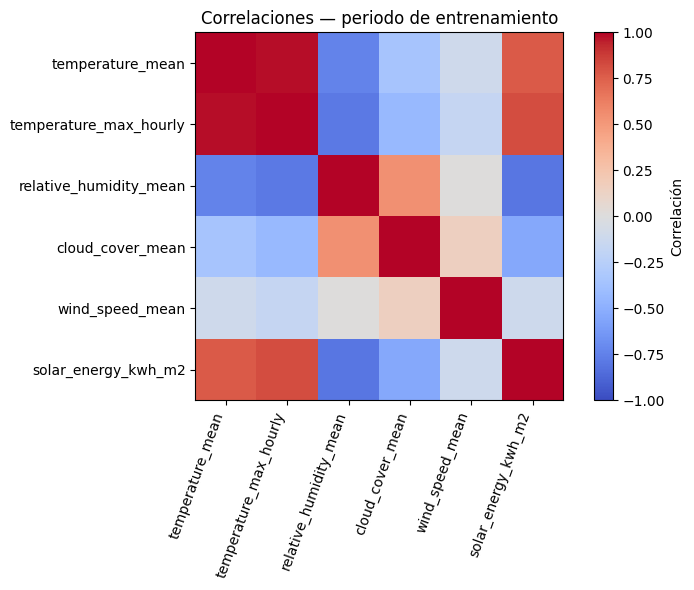

In [4]:
solar_df["date"] = pd.to_datetime(solar_df["date"])
train_for_eda = solar_df.loc[solar_df["date"] < "2023-01-01"].copy()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(solar_df["date"], solar_df[TARGET], linewidth=0.6)
ax.set(title=f"Energía solar diaria estimada — {CITY}", xlabel="Fecha", ylabel="kWh/m²/día")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "serie_temporal.png", dpi=140)
plt.show()
print("Resumen del conjunto de entrenamiento (hasta 2022):")
display(train_for_eda.describe(include="all").T)

eda_columns = [
    "temperature_mean", "temperature_max_hourly", "relative_humidity_mean",
    "cloud_cover_mean", "wind_speed_mean", TARGET,
]
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(train_for_eda[eda_columns].corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_columns)), eda_columns, rotation=70, ha="right")
ax.set_yticks(range(len(eda_columns)), eda_columns)
fig.colorbar(image, ax=ax, label="Correlación")
ax.set_title("Correlaciones — periodo de entrenamiento")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlaciones_entrenamiento.png", dpi=140)
plt.show()

## 5. Variables y partición cronológica

Las variables predictoras son meteorología observada y estacionalidad determinista del calendario. La selección se fija antes de evaluar el test. No se imputan valores con estadísticas calculadas sobre fechas futuras: se excluyen únicamente filas incompletas. La partición es entrenamiento antes de 2023, validación 2023 y test final 2024.

In [5]:
solar_df["day_of_year"] = solar_df["date"].dt.dayofyear
annual_phase = 2 * np.pi * (solar_df["day_of_year"] - 1) / 365.25
solar_df["year_sin"] = np.sin(annual_phase)
solar_df["year_cos"] = np.cos(annual_phase)

FEATURES = [
    "temperature_mean", "temperature_max_hourly", "relative_humidity_mean",
    "cloud_cover_mean", "wind_speed_mean", "year_sin", "year_cos",
]
forbidden_features = {TARGET, "shortwave_radiation_sum_mj_m2", "daylight_duration",
                      "shortwave_radiation_sum", "direct_radiation", "diffuse_radiation",
                      "sunshine_duration", "global_tilted_irradiance"}
assert not forbidden_features.intersection(FEATURES), "Se detectó un predictor con fuga de radiación."
model_data = solar_df.dropna(subset=[*FEATURES, TARGET]).copy()
train = model_data.loc[model_data["date"] < "2023-01-01"]
validation = model_data.loc[(model_data["date"] >= "2023-01-01") & (model_data["date"] < "2024-01-01")]
test = model_data.loc[(model_data["date"] >= "2024-01-01") & (model_data["date"] < "2025-01-01")]
if train.empty or validation.empty or test.empty:
    raise ValueError("La partición cronológica requiere datos completos en train, 2023 y 2024.")
assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()
print(f"Train: {train['date'].min().date()} – {train['date'].max().date()} ({len(train):,})")
print(f"Validación: {validation['date'].min().date()} – {validation['date'].max().date()} ({len(validation):,})")
print(f"Test: {test['date'].min().date()} – {test['date'].max().date()} ({len(test):,})")
print("Predictores:", FEATURES)

Train: 2015-01-01 – 2022-12-31 (2,922)
Validación: 2023-01-01 – 2023-12-31 (365)
Test: 2024-01-01 – 2024-12-31 (366)
Predictores: ['temperature_mean', 'temperature_max_hourly', 'relative_humidity_mean', 'cloud_cover_mean', 'wind_speed_mean', 'year_sin', 'year_cos']


## 6. Validacion cruzada temporal y comparacion de modelos

Comparamos regresi?n lineal y Random Forest. Una validaci?n cruzada expansiva (`TimeSeriesSplit`) se ejecuta ?nicamente dentro del conjunto de entrenamiento (2015?2022), manteniendo el orden temporal. Se eval?an despu?s ambos modelos en validaci?n 2023; la selecci?n se hace por menor RMSE de validaci?n. Solo al terminar esa selecci?n se ajusta el modelo elegido con entrenamiento + validaci?n y se mide una vez en el test 2024. El test no interviene en la selecci?n ni en la validaci?n cruzada.

,CV_R2_media,CV_R2_std,CV_MAE_media,CV_RMSE_media
Modelo,,,,
Regresi?n lineal,0.9333,0.0126,0.4125,0.5428
Random Forest,0.9391,0.0075,0.3484,0.5207


,R2,MAE_kWh_m2,RMSE_kWh_m2
Modelo,,,
Regresi?n lineal,0.9428,0.3772,0.5013
Random Forest,0.9583,0.2871,0.4278


Modelo seleccionado por menor RMSE de validaci?n: Random Forest


,R2,MAE_kWh_m2,RMSE_kWh_m2
Test final 2024 ? Random Forest,0.9468,0.3507,0.5027


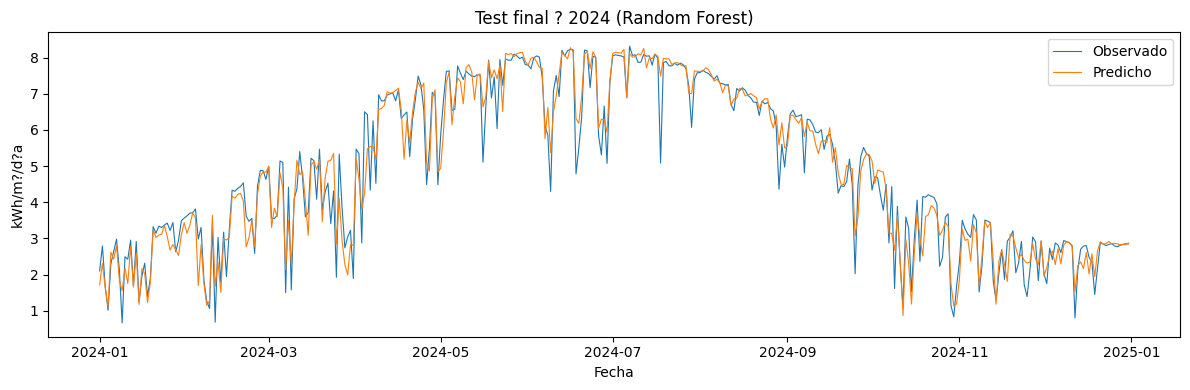

In [6]:
def regression_metrics(y_true: pd.Series, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE_kWh_m2": mean_absolute_error(y_true, y_pred),
        "RMSE_kWh_m2": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }

# CV expansiva sobre train exclusivamente; los folds conservan el orden temporal.
time_series_cv = TimeSeriesSplit(n_splits=5)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}
model_candidates = {
    "Regresi?n lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1,
    ),
}

cv_rows = []
validation_rows = []
for model_name, estimator in model_candidates.items():
    cv_scores = cross_validate(
        estimator,
        train[FEATURES],
        train[TARGET],
        cv=time_series_cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )
    cv_rows.append({
        "Modelo": model_name,
        "CV_R2_media": cv_scores["test_r2"].mean(),
        "CV_R2_std": cv_scores["test_r2"].std(),
        "CV_MAE_media": -cv_scores["test_mae"].mean(),
        "CV_RMSE_media": -cv_scores["test_rmse"].mean(),
    })

    estimator.fit(train[FEATURES], train[TARGET])
    validation_predictions = estimator.predict(validation[FEATURES])
    validation_rows.append({"Modelo": model_name, **regression_metrics(
        validation[TARGET], validation_predictions
    )})

cv_table = pd.DataFrame(cv_rows).set_index("Modelo")
validation_table = pd.DataFrame(validation_rows).set_index("Modelo")
display(cv_table.style.format("{:.4f}"))
display(validation_table.style.format("{:.4f}"))

# Se elige usando solo validaci?n 2023, antes de abrir el test final.
selected_model_name = validation_table["RMSE_kWh_m2"].idxmin()
print(f"Modelo seleccionado por menor RMSE de validaci?n: {selected_model_name}")

# Ajuste final con train + validaci?n y evaluaci?n ?nica en test 2024.
final_model = model_candidates[selected_model_name]
development = pd.concat([train, validation], ignore_index=True)
final_model.fit(development[FEATURES], development[TARGET])
test_predictions = final_model.predict(test[FEATURES])
test_metrics = regression_metrics(test[TARGET], test_predictions)
metrics_table = pd.DataFrame(
    [test_metrics], index=[f"Test final 2024 ? {selected_model_name}"]
)
display(metrics_table.style.format("{:.4f}"))

test_results = test[["date", TARGET]].copy()
test_results["prediction_kwh_m2"] = test_predictions
test_results.to_csv(PROCESSED_DIR / "test_predictions.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_results["date"], test_results[TARGET], label="Observado", linewidth=0.8)
ax.plot(test_results["date"], test_results["prediction_kwh_m2"], label="Predicho", linewidth=0.8)
ax.set(title=f"Test final ? 2024 ({selected_model_name})", xlabel="Fecha", ylabel="kWh/m?/d?a")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "prediccion_test_2024.png", dpi=140)
plt.show()

## 7. Significancia estadística con OLS

El análisis inferencial se ajusta sobre entrenamiento + validación, una vez fijado el modelo, y nunca incluye el test. Se reportan errores estándar HAC (Newey–West, 7 retardos) para considerar heterocedasticidad y autocorrelación de corto plazo, además de p-valores e intervalos de confianza del 95%. La significancia estadística no implica causalidad.

In [7]:
X_ols = sm.add_constant(development[FEATURES], has_constant="add")
ols_results = sm.OLS(development[TARGET], X_ols, missing="raise").fit(
    cov_type="HAC", cov_kwds={"maxlags": 7}
)
display(ols_results.summary())
confidence_intervals = ols_results.conf_int(alpha=0.05)
coefficient_table = pd.DataFrame({
    "coeficiente": ols_results.params,
    "error_std_HAC": ols_results.bse,
    "p_value": ols_results.pvalues,
    "IC95_inferior": confidence_intervals[0],
    "IC95_superior": confidence_intervals[1],
})
display(coefficient_table)

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     solar_energy_kwh_m2   R-squared:                       0.939
Model:                             OLS   Adj. R-squared:                  0.939
Method:                  Least Squares   F-statistic:                     4510.
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         18:38:02   Log-Likelihood:                -2593.8
No. Observations:                 3287   AIC:                             5204.
Df Residuals:                     3279   BIC:                             5252.
Df Model:                            7                                         
Covariance Type:                   HAC                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      5.6404      0.173     32.511      0.000       5.300       5.980
temperature_mean          -0.1588      0.012    -12.860      0.000      -0.183      -0.135
temperature_max_hourly     0.1731      0.011     16.435      0.000       0.152       0.194
relative_humidity_mean    -0.0206      0.001    -16.720      0.000      -0.023      -0.018
cloud_cover_mean          -0.0127      0.000    -26.806      0.000      -0.014      -0.012
wind_speed_mean           -0.0268      0.004     -6.097      0.000      -0.035      -0.018
year_sin                   0.5577      0.024     22.810      0.000       0.510       0.606
year_cos                  -1.8776      0.054    -34.526      0.000      -1.984      -1.771
==============================================================================
Omnibus:                      450.704   Durbin-Watson:                   1.481
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1282.441
Skew:                          -0.731   Prob(JB):                    3.32e-279
Kurtosis:                       5.688   Cond. No.                     1.24e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 7 lags and without small sample correction
[2] The condition number is large, 1.24e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

,coeficiente,error_std_HAC,p_value,IC95_inferior,IC95_superior
const,5.640385,0.173489,7.340336e-232,5.300353,5.980417
temperature_mean,-0.158803,0.012349,7.601857e-38,-0.183007,-0.134599
temperature_max_hourly,0.173134,0.010534,1.074855e-60,0.152486,0.193781
relative_humidity_mean,-0.020643,0.001235,9.380709e-63,-0.023063,-0.018223
cloud_cover_mean,-0.012683,0.000473,2.718776e-158,-0.013610,-0.011756
wind_speed_mean,-0.026814,0.004398,1.080551e-09,-0.035434,-0.018194
year_sin,0.557693,0.024449,3.612704e-115,0.509773,0.605612
year_cos,-1.877610,0.054382,3.222481e-261,-1.984197,-1.771024


## 8. Artefactos y limitaciones

Se guardan el modelo final, las predicciones de test y las figuras bajo `data/processed/` y `reports/figures/`. El modelo es una estimación del recurso solar incidente, no de electricidad generada por paneles: no modela eficiencia del módulo, orientación, sombras, suciedad, inversor ni pérdidas eléctricas. Para pronóstico futuro, sustituye meteorología observada por pronósticos disponibles en el momento de predicción y valida de nuevo con cortes temporales.

In [8]:
model_path = PROCESSED_DIR / "solar_best_model.joblib"
joblib.dump({"model": final_model, "model_name": selected_model_name, "features": FEATURES, "target": TARGET}, model_path)
print(f"Modelo guardado en {model_path}")
print(f"Predicciones de test: {PROCESSED_DIR / 'test_predictions.csv'}")
print(f"Figuras: {FIGURES_DIR.resolve()}")

Modelo guardado en data\processed\solar_best_model.joblib
Predicciones de test: data\processed\test_predictions.csv
Figuras: C:\Users\mario\Desktop\DC Academy\Data Science\solar-output-estimation-ml\reports\figures
